# 02 - Selection Bias (The Winner's Curse) & Feature De-Biasing

## Overview
Automated feature discovery engines explore massive hypothesis spaces. By selecting features that maximize performance metrics on the training set, these tools systematically introduce **overestimation bias**—commonly known in statistics and economics as the **"Winner's Curse"**.

In this notebook, we:
1. **Measure Selection Bias:** Quantify $\text{Bias} = \text{RIG}_{\text{train}} - \text{RIG}_{\text{unseen}}$ on benchmark datasets (Lending Club loan defaults).
2. **Analyze Search Budget & Complexity:** Observe how expanding the search space (or adding external context datasets like OpenStreetMap) amplifies bias.
3. **De-Bias Feature Importance:** Compute corrected information gain:
   $$\text{RIG}_{\text{corrected}} = \max(0, \text{RIG}_{\text{train}} - \widehat{\text{Bias}})$$
4. **Classify Feature Stability:** Use Out-of-Fold (OOF) cross-validation and Bootstrap $1\sigma$ / $2\sigma$ confidence intervals to separate genuine signals from spurious artifacts.


In [1]:
import sys
import os
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure local signalgate package is importable
sys.path.insert(0, os.path.abspath('..'))

from signalgate import (
    rig, 
    FeatureNoiseThreshold, 
    FeatureDebiaser
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


## 1. Measuring Selection Bias on Lending Club

We use the Lending Club loan defaults dataset (`Data/LC_defaults_loanStats_with_random_parition.csv.gz`).
* **Target:** `bad_loans` (binary default indicator: 1 = defaulted, 0 = paid).
* **Split:** A 10% sample (~5,400 rows) represents the primary training set where feature discovery and selection occur. The remaining 90% (~49,000 rows) represents the unseen "population".


In [2]:
filepath = '../Data/LC_defaults_loanStats_with_random_parition.csv.gz'
df_full = pd.read_csv(filepath)

# Target column
target = 'bad_loans'

# Split into train (10%) and unseen population (90%)
df_train = df_full.sample(frac=0.10, random_state=42)
df_pop = df_full.drop(df_train.index)

print(f"Full dataset shape:       {df_full.shape}")
print(f"Training sample (10%):    {df_train.shape} (Minority class rate: {df_train[target].mean():.1%})")
print(f"Unseen Population (90%):  {df_pop.shape}")


Full dataset shape:       (54655, 42)
Training sample (10%):    (5466, 42) (Minority class rate: 18.1%)
Unseen Population (90%):  (49189, 42)


In [3]:
# Identify eligible feature columns (numeric and categorical)
candidate_cols = [c for c in df_train.columns if c not in [target, 'id', 'member_id', 'splitColumn']]

# Compute Train RIG and Population RIG for each feature
df_bias = FeatureDebiaser.compute_holdout_bias(
    df_train=df_train,
    df_eval=df_pop,
    target=target,
    feature_cols=candidate_cols,
    eval_label='population'
)

df_bias.head(10)


,feature,train_rig,population_rig,population_bias,overfitting_ratio_population
0,desc,1.000000,0.997412,0.002588,0.002588
1,payment_inc_ratio,0.979128,0.889189,0.089939,0.091857
2,emp_title,0.913616,0.799974,0.113642,0.124387
3,revol_bal,0.905022,0.564204,0.340817,0.376585
4,installment,0.799473,0.488264,0.311209,0.389268
5,interest,0.776391,0.485181,0.291210,0.375082
6,title,0.538827,0.415789,0.123038,0.228344
7,dti,0.486530,0.096045,0.390485,0.802592
8,funded_amnt_inv,0.276283,0.129312,0.146971,0.531959
9,revol_util,0.237290,0.034899,0.202390,0.852925


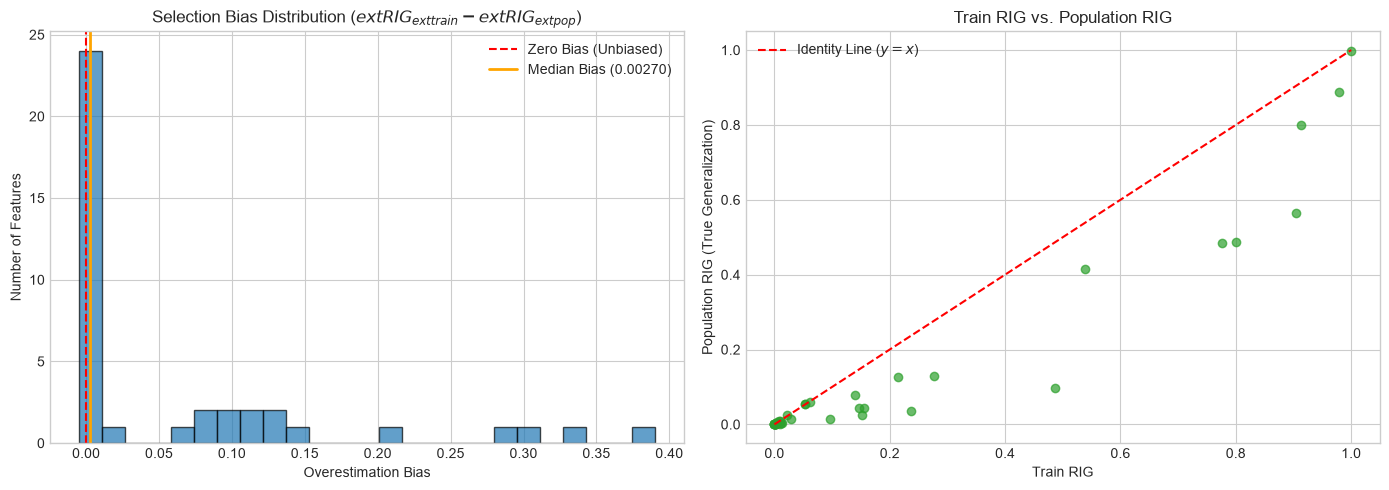

Features with positive bias (Train > Population): 67.5%
Median Overestimation Bias: 0.00270


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of Population Bias
median_bias = df_bias['population_bias'].median()
mean_bias = df_bias['population_bias'].mean()

axes[0].hist(df_bias['population_bias'], bins=25, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].axvline(0, color='red', linestyle='--', label='Zero Bias (Unbiased)')
axes[0].axvline(median_bias, color='orange', linestyle='-', lw=2, label=f'Median Bias ({median_bias:.5f})')
axes[0].set_title('Selection Bias Distribution ($\text{RIG}_{\text{train}} - \text{RIG}_{\text{pop}}$)', fontsize=12)
axes[0].set_xlabel('Overestimation Bias')
axes[0].set_ylabel('Number of Features')
axes[0].legend()

# Scatter: Train RIG vs Population RIG
axes[1].scatter(df_bias['train_rig'], df_bias['population_rig'], alpha=0.7, color='#2ca02c')
max_val = max(df_bias['train_rig'].max(), df_bias['population_rig'].max())
axes[1].plot([0, max_val], [0, max_val], 'r--', label='Identity Line ($y = x$)')
axes[1].set_title('Train RIG vs. Population RIG', fontsize=12)
axes[1].set_xlabel('Train RIG')
axes[1].set_ylabel('Population RIG (True Generalization)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Features with positive bias (Train > Population): {(df_bias['population_bias'] > 0).mean():.1%}")
print(f"Median Overestimation Bias: {median_bias:.5f}")


## 2. Linking Selection Bias to Search Space Size ($M$)

Why is the median bias systematically positive?

When an algorithm searches through candidate transformations, candidate features are subject to random sample variance. Selecting top performers acts as a maximum order statistic filter:
$$\text{Bias} = \text{RIG}_{\text{train}} - \text{RIG}_{\text{true}} \approx \mathbb{E}[\text{Noise Filter Floor}]$$

As demonstrated in Slide 12 and Slide 23 of the internal deck:
1. **Bias scales with search complexity:** As learning complexity increases (generating more feature variations), median bias increases linearly.
2. **Expanding context (e.g. OpenStreetMap):** Evaluating external context datasets increases the candidate pool size $M$ by orders of magnitude, inflating median bias by **up to 4x** unless the selection threshold is adjusted.


## 3. Feature De-Biasing & Stability Classification

To prevent overfitting and false discoveries, we implement the two-stage de-biasing framework:
1. **Bias Correction:**
   $$\text{RIG}_{\text{corrected}} = \max(0, \text{RIG}_{\text{train}} - \widehat{\text{Bias}})$$
   where $\widehat{\text{Bias}}$ is estimated via holdout, Out-of-Fold cross-validation, or the theoretical EVT noise floor.
2. **Bootstrap Confidence Testing ($1\sigma$ and $2\sigma$ Stability):**
   We draw $B$ bootstrap resamples to compute the empirical standard error $\sigma_{\text{boot}}$ of each feature:
   * **Highly Stable ($2\sigma$):** $\text{RIG}_{\text{corrected}} - 2\sigma_{\text{boot}} > 0$
   * **Moderately Stable ($1\sigma$):** $\text{RIG}_{\text{corrected}} - \sigma_{\text{boot}} > 0$
   * **Unstable / Spurious:** $\text{RIG}_{\text{corrected}} - \sigma_{\text{boot}} \le 0$


In [5]:
# Run bootstrap stability analysis using estimated median bias
df_stability = FeatureDebiaser.bootstrap_stability_analysis(
    df=df_train,
    target=target,
    feature_cols=candidate_cols,
    estimated_bias=median_bias,
    n_bootstraps=100,
    seed=42
)

# Merge with true population RIG to evaluate correctness
df_merged = df_stability.merge(
    df_bias[['feature', 'population_rig', 'overfitting_ratio_population']], 
    on='feature'
)

print("Stability Summary:")
print(df_merged['stability_class'].value_counts())
df_merged.head(10)


Stability Summary:
stability_class
Highly Stable (2-Sigma)        25
Unstable / Noise               14
Moderately Stable (1-Sigma)     1
Name: count, dtype: int64


,feature,train_rig,estimated_bias,corrected_rig,sigma_boot,is_1_sigma,is_2_sigma,stability_class,population_rig,overfitting_ratio_population
0,desc,1.000000,0.002704,0.997296,6.412856e-15,True,True,Highly Stable (2-Sigma),0.997412,0.002588
1,payment_inc_ratio,0.979128,0.002704,0.976425,2.494162e-03,True,True,Highly Stable (2-Sigma),0.889189,0.091857
2,emp_title,0.913616,0.002704,0.910913,5.645642e-03,True,True,Highly Stable (2-Sigma),0.799974,0.124387
3,revol_bal,0.905022,0.002704,0.902318,5.860170e-03,True,True,Highly Stable (2-Sigma),0.564204,0.376585
4,installment,0.799473,0.002704,0.796769,7.802195e-03,True,True,Highly Stable (2-Sigma),0.488264,0.389268
5,interest,0.776391,0.002704,0.773688,9.232472e-03,True,True,Highly Stable (2-Sigma),0.485181,0.375082
6,title,0.538827,0.002704,0.536124,1.229417e-02,True,True,Highly Stable (2-Sigma),0.415789,0.228344
7,dti,0.486530,0.002704,0.483826,1.109604e-02,True,True,Highly Stable (2-Sigma),0.096045,0.802592
8,funded_amnt_inv,0.276283,0.002704,0.273579,1.077524e-02,True,True,Highly Stable (2-Sigma),0.129312,0.531959
9,revol_util,0.237290,0.002704,0.234586,9.217740e-03,True,True,Highly Stable (2-Sigma),0.034899,0.852925


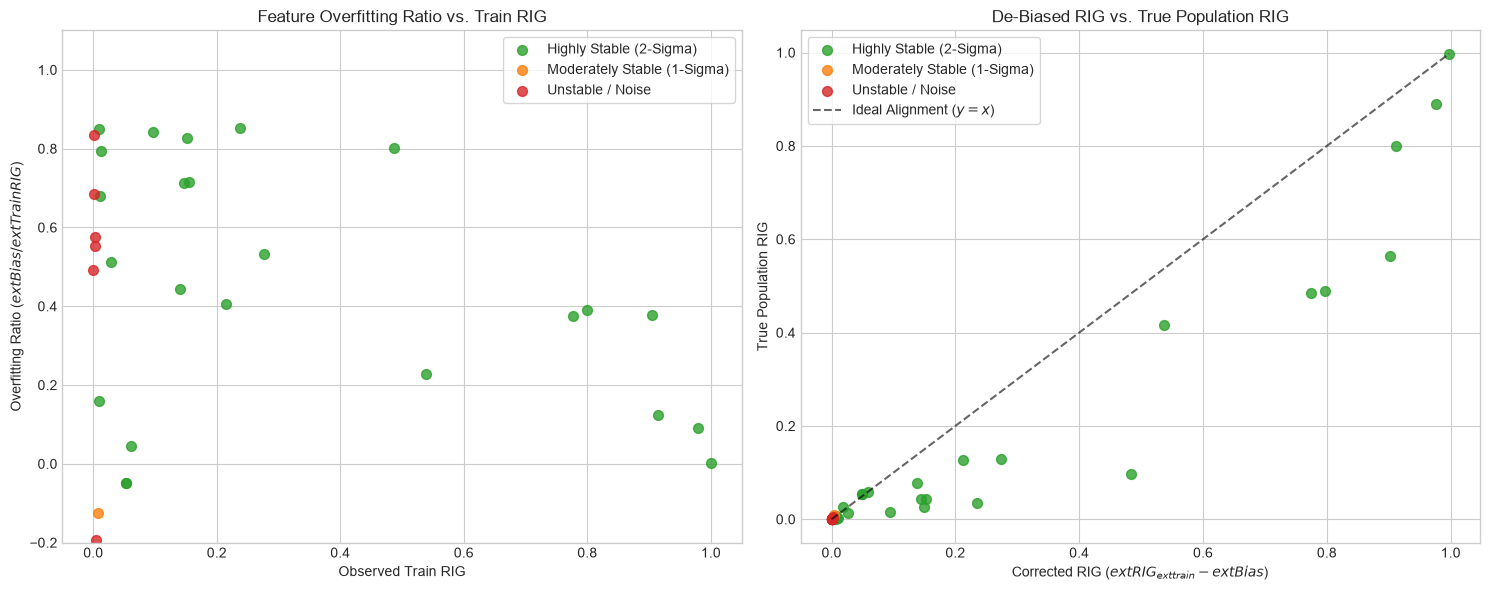

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

color_map = {
    'Highly Stable (2-Sigma)': '#2ca02c',
    'Moderately Stable (1-Sigma)': '#ff7f0e',
    'Unstable / Noise': '#d62728'
}
colors = df_merged['stability_class'].map(color_map)

# Left: Train RIG vs Overfitting Ratio
for cls_name, color in color_map.items():
    subset = df_merged[df_merged['stability_class'] == cls_name]
    axes[0].scatter(subset['train_rig'], subset['overfitting_ratio_population'], 
                    c=color, label=cls_name, alpha=0.8, s=50)

axes[0].set_title('Feature Overfitting Ratio vs. Train RIG', fontsize=12)
axes[0].set_xlabel('Observed Train RIG')
axes[0].set_ylabel('Overfitting Ratio ($\text{Bias} / \text{Train RIG}$)')
axes[0].set_ylim(-0.2, 1.1)
axes[0].legend(frameon=True)

# Right: Corrected RIG vs True Population RIG
for cls_name, color in color_map.items():
    subset = df_merged[df_merged['stability_class'] == cls_name]
    axes[1].scatter(subset['corrected_rig'], subset['population_rig'], 
                    c=color, label=cls_name, alpha=0.8, s=50)

max_r = max(df_merged['corrected_rig'].max(), df_merged['population_rig'].max())
axes[1].plot([0, max_r], [0, max_r], 'k--', alpha=0.6, label='Ideal Alignment ($y = x$)')
axes[1].set_title('De-Biased RIG vs. True Population RIG', fontsize=12)
axes[1].set_xlabel('Corrected RIG ($\text{RIG}_{\text{train}} - \text{Bias}$)')
axes[1].set_ylabel('True Population RIG')
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


## 4. Summary & Best Practices

1. **Never trust raw training metric scores from high-dimensional search:** When thousands of candidate features are explored, the top ranked features will have inflated metrics purely due to selection bias.
2. **Measure or estimate the bias floor:** Use holdouts, Out-of-Fold (OOF) cross-validation, or the analytical EVT threshold to determine the noise floor.
3. **Filter by Stability ($2\sigma$):** Requiring $\text{RIG}_{\text{corrected}} - 2\sigma_{\text{boot}} > 0$ filters out spurious features with high probability and protects downstream machine learning models from overfitting.
